In [1]:


import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline


In [3]:
# ============================================================
# 2. CHARGEMENT DES DONNÉES
# ============================================================

DATA_PATH = "../data/processed/clustering_data.csv"

df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("CHARGEMENT DES DONNÉES")
print("=" * 70)

print("Shape :", df.shape)
print("\nColonnes :")
print(df.columns.tolist())

print("\nAperçu :")
print(df.head())

CHARGEMENT DES DONNÉES
Shape : (768, 11)

Colonnes :
['Unnamed: 0', 'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Cluster', 'risk_category']

Aperçu :
   Unnamed: 0  Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  \
0           0            6    148.0           72.0           35.0    255.0   
1           1            1     85.0           66.0           29.0     48.6   
2           2            8    183.0           64.0           24.4    228.4   
3           3            1     89.0           66.0           23.0     94.0   
4           4            0    137.0           40.0           35.0    168.0   

    BMI  DiabetesPedigreeFunction   Age  Cluster risk_category  
0  33.6                     0.627  50.0        0     High Risk  
1  26.6                     0.351  31.0        1      Low Risk  
2  23.3                     0.672  32.0        0     High Risk  
3  28.1                     0.167  21.0        1    

In [4]:
# ============================================================
# 3. DÉFINITION DE X ET y
# ============================================================

features = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

# X = variables explicatives
X = df[features]

# y = Cluster obtenu avec K-Means
y = df["Cluster"]


print("\n" + "=" * 70)
print("VARIABLES X ET y")
print("=" * 70)

print("X shape :", X.shape)
print("y shape :", y.shape)

print("\nDistribution des classes :")
print(y.value_counts())

print("\nPourcentage des classes :")
print(
    y.value_counts(normalize=True).mul(100).round(2)
)


VARIABLES X ET y
X shape : (768, 7)
y shape : (768,)

Distribution des classes :
Cluster
1    444
0    324
Name: count, dtype: int64

Pourcentage des classes :
Cluster
1    57.81
0    42.19
Name: proportion, dtype: float64


In [5]:
# ============================================================
# 4. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

print("\nTrain classes :")
print(y_train.value_counts())

print("\nTest classes :")
print(y_test.value_counts())


TRAIN / TEST SPLIT
X_train : (614, 7)
X_test  : (154, 7)

Train classes :
Cluster
1    355
0    259
Name: count, dtype: int64

Test classes :
Cluster
1    89
0    65
Name: count, dtype: int64


In [6]:
# ============================================================
# 5. STANDARDISATION
# ============================================================
# Ici on fait une première comparaison des modèles.
# Le scaler est FIT uniquement sur train.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


In [7]:
# ============================================================
# 6. RANDOM OVERSAMPLER
# ============================================================

ros = RandomOverSampler(
    random_state=42
)

X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train_scaled,
    y_train
)

print("\n" + "=" * 70)
print("RANDOM OVERSAMPLER")
print("=" * 70)

print("Avant :")
print(y_train.value_counts())

print("\nAprès :")
print(pd.Series(y_train_resampled).value_counts())


RANDOM OVERSAMPLER
Avant :
Cluster
1    355
0    259
Name: count, dtype: int64

Après :
Cluster
0    355
1    355
Name: count, dtype: int64


In [8]:

# ============================================================
# 7. DÉFINITION DES 3 MODÈLES
# ============================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(
        random_state=42
    )
}

In [9]:
# ============================================================
# 8. ENTRAÎNEMENT + PRÉDICTION
# ============================================================

predictions = {}

trained_models = {}

for name, model in models.items():

    print("\nEntraînement :", name)

    # Training
    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    # Prediction
    y_pred = model.predict(
        X_test_scaled
    )

    trained_models[name] = model
    predictions[name] = y_pred


Entraînement : Logistic Regression

Entraînement : Random Forest

Entraînement : SVM


In [10]:

# ============================================================
# 9. FONCTION D'ÉVALUATION
# ============================================================

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-score  : {f1:.4f}")

    print("\nClassification Report :")

    print(
        classification_report(
            y_true,
            y_pred,
            zero_division=0
        )
    )

    print("Confusion Matrix :")

    print(
        confusion_matrix(
            y_true,
            y_pred
        )
    )

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }


In [11]:
# ============================================================
# 10. ÉVALUATION DES 3 MODÈLES
# ============================================================

results = []

for name, y_pred in predictions.items():

    result = evaluate_model(
        name,
        y_test,
        y_pred
    )

    results.append(result)


# ============================================================
# 11. COMPARAISON DES MODÈLES
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

print("\n" + "=" * 70)
print("COMPARAISON DES MODÈLES")
print("=" * 70)

print(
    results_df.to_string(index=False)
)


Logistic Regression
Accuracy  : 0.9870
Precision : 1.0000
Recall    : 0.9775
F1-score  : 0.9886

Classification Report :
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        65
           1       1.00      0.98      0.99        89

    accuracy                           0.99       154
   macro avg       0.99      0.99      0.99       154
weighted avg       0.99      0.99      0.99       154

Confusion Matrix :
[[65  0]
 [ 2 87]]

Random Forest
Accuracy  : 0.9481
Precision : 0.9655
Recall    : 0.9438
F1-score  : 0.9545

Classification Report :
              precision    recall  f1-score   support

           0       0.93      0.95      0.94        65
           1       0.97      0.94      0.95        89

    accuracy                           0.95       154
   macro avg       0.95      0.95      0.95       154
weighted avg       0.95      0.95      0.95       154

Confusion Matrix :
[[62  3]
 [ 5 84]]

SVM
Accuracy  : 0.9805
Precisio

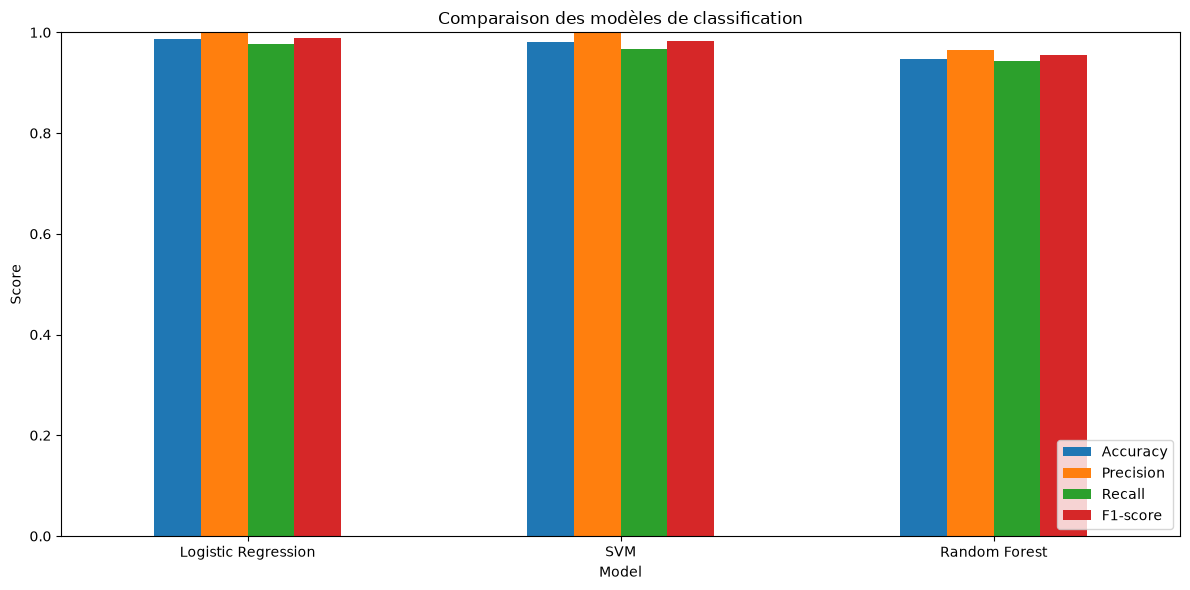

In [12]:
# ============================================================
# 12. VISUALISATION DE LA COMPARAISON
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparaison des modèles de classification")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [13]:

# ============================================================
# 14. GRIDSEARCH — RANDOM FOREST
# ============================================================

print("\n" + "=" * 70)
print("GRIDSEARCH — RANDOM FOREST")
print("=" * 70)

rf = RandomForestClassifier(
    random_state=42
)

param_grid_rf = {

    "n_estimators": [
        100,
        200,
        300
    ],

    "max_depth": [
        None,
        5,
        10,
        20
    ],

    "min_samples_split": [
        2,
        5,
        10
    ],

    "min_samples_leaf": [
        1,
        2,
        4
    ]
}


grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(
    X_train_resampled,
    y_train_resampled
)

print("\nMeilleurs paramètres RF :")
print(grid_rf.best_params_)

print("\nMeilleur F1 CV RF :")
print(grid_rf.best_score_)


# ============================================================
# 15. GRIDSEARCH — LOGISTIC REGRESSION
# ============================================================

print("\n" + "=" * 70)
print("GRIDSEARCH — LOGISTIC REGRESSION")
print("=" * 70)

lr = LogisticRegression(
    max_iter=2000,
    random_state=42
)

param_grid_lr = {

    "C": [
        0.01,
        0.1,
        1,
        10,
        100
    ],

    "solver": [
        "liblinear",
        "lbfgs"
    ]
}


grid_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_lr.fit(
    X_train_resampled,
    y_train_resampled
)

print("\nMeilleurs paramètres LR :")
print(grid_lr.best_params_)

print("\nMeilleur F1 CV LR :")
print(grid_lr.best_score_)


# ============================================================
# 16. GRIDSEARCH — SVM
# ============================================================

print("\n" + "=" * 70)
print("GRIDSEARCH — SVM")
print("=" * 70)

svm = SVC(
    random_state=42
)

param_grid_svm = {

    "C": [
        0.1,
        1,
        10,
        100
    ],

    "kernel": [
        "linear",
        "rbf"
    ],

    "gamma": [
        "scale",
        "auto"
    ]
}


grid_svm = GridSearchCV(
    estimator=svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_svm.fit(
    X_train_resampled,
    y_train_resampled
)

print("\nMeilleurs paramètres SVM :")
print(grid_svm.best_params_)

print("\nMeilleur F1 CV SVM :")
print(grid_svm.best_score_)


GRIDSEARCH — RANDOM FOREST
Fitting 5 folds for each of 108 candidates, totalling 540 fits

Meilleurs paramètres RF :
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Meilleur F1 CV RF :
0.9558639873183792

GRIDSEARCH — LOGISTIC REGRESSION

Meilleurs paramètres LR :
{'C': 100, 'solver': 'liblinear'}

Meilleur F1 CV LR :
0.9943660574766359

GRIDSEARCH — SVM

Meilleurs paramètres SVM :
{'C': 100, 'gamma': 'scale', 'kernel': 'linear'}

Meilleur F1 CV SVM :
0.9957843574864851


In [14]:

# ============================================================
# 17. PRÉDICTIONS DES MODÈLES OPTIMISÉS
# ============================================================

best_lr = grid_lr.best_estimator_

best_rf = grid_rf.best_estimator_

best_svm = grid_svm.best_estimator_


y_pred_lr_tuned = best_lr.predict(
    X_test_scaled
)

y_pred_rf_tuned = best_rf.predict(
    X_test_scaled
)

y_pred_svm_tuned = best_svm.predict(
    X_test_scaled
)


In [15]:

# ============================================================
# 18. ÉVALUATION DES MODÈLES OPTIMISÉS
# ============================================================

tuned_predictions = {

    "Logistic Regression Tuned":
        y_pred_lr_tuned,

    "Random Forest Tuned":
        y_pred_rf_tuned,

    "SVM Tuned":
        y_pred_svm_tuned
}


tuned_results = []

for name, y_pred in tuned_predictions.items():

    result = evaluate_model(
        name,
        y_test,
        y_pred
    )

    tuned_results.append(result)




Logistic Regression Tuned
Accuracy  : 0.9935
Precision : 1.0000
Recall    : 0.9888
F1-score  : 0.9944

Classification Report :
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        65
           1       1.00      0.99      0.99        89

    accuracy                           0.99       154
   macro avg       0.99      0.99      0.99       154
weighted avg       0.99      0.99      0.99       154

Confusion Matrix :
[[65  0]
 [ 1 88]]

Random Forest Tuned
Accuracy  : 0.9481
Precision : 0.9765
Recall    : 0.9326
F1-score  : 0.9540

Classification Report :
              precision    recall  f1-score   support

           0       0.91      0.97      0.94        65
           1       0.98      0.93      0.95        89

    accuracy                           0.95       154
   macro avg       0.94      0.95      0.95       154
weighted avg       0.95      0.95      0.95       154

Confusion Matrix :
[[63  2]
 [ 6 83]]

SVM Tuned
Accuracy 

In [16]:
# ============================================================
# 19. COMPARAISON FINALE
# ============================================================

tuned_results_df = pd.DataFrame(
    tuned_results
)

tuned_results_df = tuned_results_df.sort_values(
    by="F1-score",
    ascending=False
)

print("\n" + "=" * 70)
print("COMPARAISON FINALE APRÈS GRIDSEARCH")
print("=" * 70)

print(
    tuned_results_df.to_string(index=False)
)


COMPARAISON FINALE APRÈS GRIDSEARCH
                    Model  Accuracy  Precision   Recall  F1-score
Logistic Regression Tuned  0.993506   1.000000 0.988764  0.994350
                SVM Tuned  0.993506   1.000000 0.988764  0.994350
      Random Forest Tuned  0.948052   0.976471 0.932584  0.954023


In [17]:
# ============================================================
# 20. CHOISIR LE MEILLEUR MODÈLE
# ============================================================

best_model_name = tuned_results_df.iloc[0]["Model"]

print("\n" + "=" * 70)
print("MEILLEUR MODÈLE")
print("=" * 70)

print(
    "Meilleur modèle selon F1-score :",
    best_model_name
)


MEILLEUR MODÈLE
Meilleur modèle selon F1-score : Logistic Regression Tuned


In [18]:

# ============================================================
# 21. RÉCUPÉRER LE MEILLEUR ESTIMATEUR
# ============================================================

best_estimators = {

    "Logistic Regression Tuned":
        best_lr,

    "Random Forest Tuned":
        best_rf,

    "SVM Tuned":
        best_svm
}

best_estimator = best_estimators[
    best_model_name
]

print("\nMeilleur estimateur :")
print(best_estimator)


Meilleur estimateur :
LogisticRegression(C=100, max_iter=2000, random_state=42, solver='liblinear')


In [19]:
# ============================================================
# 22. PIPELINE FINAL
# ============================================================

print("\n" + "=" * 70)
print("CONSTRUCTION DU PIPELINE FINAL")
print("=" * 70)

final_pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "oversampler",
        RandomOverSampler(
            random_state=42
        )
    ),

    (
        "model",
        best_estimator
    )
])



CONSTRUCTION DU PIPELINE FINAL


In [20]:
# ============================================================
# 23. ENTRAÎNEMENT DU PIPELINE FINAL
# ============================================================

final_pipeline.fit(
    X_train,
    y_train
)

print("Pipeline entraîné avec succès.")


# ============================================================
# 24. TEST DU PIPELINE FINAL
# ============================================================

y_pred_final = final_pipeline.predict(
    X_test
)


print("\nRésultats du Pipeline Final :")

final_result = evaluate_model(
    "FINAL PIPELINE",
    y_test,
    y_pred_final
)

Pipeline entraîné avec succès.

Résultats du Pipeline Final :

FINAL PIPELINE
Accuracy  : 0.9935
Precision : 1.0000
Recall    : 0.9888
F1-score  : 0.9944

Classification Report :
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        65
           1       1.00      0.99      0.99        89

    accuracy                           0.99       154
   macro avg       0.99      0.99      0.99       154
weighted avg       0.99      0.99      0.99       154

Confusion Matrix :
[[65  0]
 [ 1 88]]


In [22]:
# ============================================================
# 25. SAUVEGARDER LE PIPELINE
# ============================================================

MODEL_DIR = "../models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

MODEL_PATH = (
    "../models/diabetes_cluster_pipeline.joblib"
)

joblib.dump(
    final_pipeline,
    MODEL_PATH
)

print("\n" + "=" * 70)
print("SAUVEGARDE")
print("=" * 70)

print(
    f"Pipeline sauvegardé dans : {MODEL_PATH}"
)


SAUVEGARDE
Pipeline sauvegardé dans : ../models/diabetes_cluster_pipeline.joblib


In [23]:

# ============================================================
# 26. TEST DU MODÈLE SAUVEGARDÉ
# ============================================================

loaded_pipeline = joblib.load(
    MODEL_PATH
)

test_predictions = loaded_pipeline.predict(
    X_test.iloc[:5]
)

print("\nPrédictions du modèle sauvegardé :")
print(test_predictions)


# ============================================================
# 27. RÉSUMÉ FINAL
# ============================================================

print("\n" + "=" * 70)
print("RÉSUMÉ DU PROJET")
print("=" * 70)

print("Nombre de variables :", len(features))

print(
    "Nombre observations :",
    len(df)
)

print(
    "Meilleur modèle :",
    best_model_name
)

print(
    "Accuracy finale :",
    f"{final_result['Accuracy']:.4f}"
)

print(
    "Precision finale :",
    f"{final_result['Precision']:.4f}"
)

print(
    "Recall finale :",
    f"{final_result['Recall']:.4f}"
)

print(
    "F1-score final :",
    f"{final_result['F1-score']:.4f}"
)

print(
    "\nModèle disponible ici :",
    MODEL_PATH
)


Prédictions du modèle sauvegardé :
[0 0 1 0 0]

RÉSUMÉ DU PROJET
Nombre de variables : 7
Nombre observations : 768
Meilleur modèle : Logistic Regression Tuned
Accuracy finale : 0.9935
Precision finale : 1.0000
Recall finale : 0.9888
F1-score final : 0.9944

Modèle disponible ici : ../models/diabetes_cluster_pipeline.joblib
